# Étape 4 — Optimisation et évaluation

Objectif : améliorer les performances des modèles retenus à l'étape 3 en affinant leurs hyperparamètres (**GridSearchCV / RandomizedSearchCV**), comparer les modèles optimisés sur le **jeu de test indépendant**, analyser leurs erreurs, puis choisir et sauvegarder le **pipeline complet** (prétraitement + modèle) pour l'étape 5 (app Streamlit, DAG Airflow).

Bilan de l'étape 3 (jeu de test indépendant, cible à 3 classes, métriques pondérées) :

| Modèle | F1 Score | Accuracy | ROC AUC |
|---|---|---|---|
| **Logistic Regression** | **0.7575** | 0.7575 | **0.9150** |
| SVM | 0.7214 | 0.7225 | 0.8944 |
| Random Forest | 0.6721 | 0.6775 | 0.8528 |

**Modèles retenus pour l'optimisation : Logistic Regression et SVM** (les deux meilleurs, résultats proches). Random Forest est écarté : nettement en dessous sur toutes les métriques — un modèle d'arbres modélise mal les relations essentiellement linéaires/monotones (effet "dose") que montrent les variables de mode de vie vis-à-vis du risque (cf. corrélations de l'EDA).

## 1. Chargement des données et modèles de référence

On recharge les données préparées à l'étape 2 (`train.csv` / `test.csv` + `preprocessor.pkl`), ainsi que les modèles de référence (mêmes hyperparamètres qu'à l'étape 3, `random_state` identique → résultats reproductibles) pour construire un tableau **avant / après optimisation**.

Le baseline de la Logistic Regression est celui sauvegardé à l'étape 3 ; les deux autres sont ré-instanciés puis ré-entraînés à l'identique.


In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

sns.set_theme(style="whitegrid")

ROOT_DIR = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
import sys; sys.path.insert(0, str(ROOT_DIR / "src"))
DATA_PROCESSED_DIR = ROOT_DIR / "data" / "processed"
MODELS_DIR = ROOT_DIR / "models"
MODELS_DIR.mkdir(exist_ok=True)

# Chargement des jeux train et test bruts, puis transformation via le preprocessor
train_df = pd.read_csv(DATA_PROCESSED_DIR / "train.csv")
test_df = pd.read_csv(DATA_PROCESSED_DIR / "test.csv")
TARGET = "Mental_Health_Risk"

y_train = train_df[TARGET]
y_test = test_df[TARGET]

preprocessor = joblib.load(DATA_PROCESSED_DIR / "preprocessor.pkl")
X_train = preprocessor.transform(train_df.drop(columns=[TARGET]))
X_test = preprocessor.transform(test_df.drop(columns=[TARGET]))
# Chargement des jeux train et test bruts, puis transformation via le preprocessor
train_df = pd.read_csv(DATA_PROCESSED_DIR / "train.csv")
test_df = pd.read_csv(DATA_PROCESSED_DIR / "test.csv")
TARGET = "Mental_Health_Risk"

y_train = train_df[TARGET]
y_test = test_df[TARGET]

preprocessor = joblib.load(DATA_PROCESSED_DIR / "preprocessor.pkl")
X_train = preprocessor.transform(train_df.drop(columns=[TARGET]))
X_test = preprocessor.transform(test_df.drop(columns=[TARGET]))

RISK_ORDER = ["Low", "Medium", "High"]

BASELINES = {
    "Logistic Regression": joblib.load(MODELS_DIR / "logistic_regression_baseline.pkl"),
    "SVM": Pipeline([("classifier", SVC(random_state=42))]),
    "Random Forest": Pipeline([("classifier", RandomForestClassifier(n_estimators=100, random_state=42))]),
}

# La LR baseline est déjà fit (étape 3) ; on (re)fit les deux autres sur le train,
# mêmes hyperparamètres et random_state qu'à l'étape 3 -> résultats identiques.
for model in BASELINES.values():
    if not hasattr(model, "classes_"):
        model.fit(X_train, y_train)


def evaluate(model, X, y_true, name):
    """Métriques pondérées (cible multiclasse) sur un jeu donné."""
    pred = model.predict(X)
    # ROC-AUC multiclasse : sklearn >= 1.9 exige de vraies probabilités
    # (somme à 1 par ligne). SVC(probability=True) étant déprécié, le ROC-AUC
    # n'est calculé que pour les modèles probabilistes (NaN sinon) ;
    # la comparaison se fait sur le F1 / l'Accuracy, non affectés.
    if hasattr(model, "predict_proba"):
        auc = roc_auc_score(y_true, model.predict_proba(X),
                            multi_class="ovr", average="weighted")
        auc = np.nan
    return {
        "Model": name,
        "Recall": recall_score(y_true, pred, average="weighted"),
        "Precision": precision_score(y_true, pred, average="weighted"),
        "F1 Score": f1_score(y_true, pred, average="weighted"),
        "Accuracy": accuracy_score(y_true, pred),
        "ROC AUC": auc,
    }


baseline_results = pd.DataFrame(
    [evaluate(model, X_test, y_test, name) for name, model in BASELINES.items()]
)
print(baseline_results.round(4).to_string(index=False))

Train : (1600, 21) | Test : (400, 21)


              Model  Recall  Precision  F1 Score  Accuracy  ROC AUC
Logistic Regression  0.7575     0.7576    0.7575    0.7575   0.9150
                SVM  0.7225     0.7205    0.7214    0.7225      NaN
      Random Forest  0.6775     0.6696    0.6721    0.6775   0.8528


## 2. Optimisation de la Logistic Regression — GridSearchCV

**Hyperparamètre exploré :** `C` (inverse de la force de régularisation) — petite valeur = régularisation forte (modèle simple, moins de sur-apprentissage), grande valeur = modèle plus souple. C'est **le** paramètre clé de la régression logistique régularisée.

**Choix du solveur :** on garde `lbfgs`, le solveur **multinomial** (un seul modèle apprend les 3 classes via softmax, cf. étape 3). Le solveur `liblinear` — historiquement utilisé en One-vs-Rest — **n'accepte plus les cibles à 3 classes** dans les versions récentes de sklearn (erreur `does not support multiclass classification`) : un essai avec lui fait échouer les fits, on s'en tient donc à `lbfgs`.

**Choix de GridSearchCV :** l'espace de recherche est petit (5 valeurs de `C`) → exploration exhaustive possible sans coût.

**Scoring : `f1_weighted`** — la métrique retenue à l'étape 3 pour classer les modèles (cible multiclasse, moyenne pondérée par la taille des classes). Validation croisée `cv=5` stratifiée (la répartition ~33/33/34 est conservée dans chaque fold), `n_jobs=-1` pour paralléliser.

In [2]:
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
}

grid_search = GridSearchCV(
    BASELINES["Logistic Regression"],
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=5,
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)

print(f"Meilleurs paramètres : {grid_search.best_params_}")
print(f"F1 pondéré (validation croisée, train) : {grid_search.best_score_:.4f}")

grid_results = (
    pd.DataFrame(grid_search.cv_results_)
    [["param_classifier__C", "mean_test_score", "rank_test_score"]]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)
grid_results.head(10)

Meilleurs paramètres : {'classifier__C': 1}
F1 pondéré (validation croisée, train) : 0.7533


,param_classifier__C,mean_test_score,rank_test_score
0,1.00,0.753270,1
1,10.00,0.752085,2
2,100.00,0.752085,2
3,0.10,0.741476,4
4,0.01,0.701498,5


## 3. Optimisation du SVM — RandomizedSearchCV

**Hyperparamètres explorés :**

- `C` : tolérance aux erreurs d'entraînement (régularisation) — trop petit = sous-apprentissage, trop grand = sur-apprentissage ;
- `gamma` : rayon d'influence de chaque point pour le noyau `rbf` — petit = frontières lisses et générales, grand = frontières complexes (risque de sur-apprentissage) ;
- `kernel` : `rbf` (frontières non linéaires) vs `linear` (frontière linéaire, comparable à la régression logistique).

**Choix de RandomizedSearchCV :** l'espace complet (4 × 4 × 2 = 32 combinaisons) serait coûteux à explorer exhaustivement pour un SVM, dont l'entraînement est plus lent. L'échantillonnage aléatoire (`n_iter=12`) explore efficacement l'espace à coût maîtrisé — c'est le cas d'usage typique de RandomizedSearchCV.

**Remarque :** on optimise le SVM **sans** `probability=True` (déprécié depuis sklearn 1.9, cf. warning à l'étape 3). Conséquence : sklearn >= 1.9 exigeant de vraies probabilités pour le ROC-AUC multiclasse, cette métrique n'est pas calculée pour le SVM (NaN dans les tableaux) — la comparaison repose sur le F1 / l'Accuracy, qui ne dépendent pas de la calibration. Une calibration (`CalibratedClassifierCV`) ne serait utile que si le SVM était finalement retenu.

In [3]:
param_distributions = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", 0.01, 0.1, 1],
    "classifier__kernel": ["rbf", "linear"],
}

random_search = RandomizedSearchCV(
    BASELINES["SVM"],
    param_distributions=param_distributions,
    n_iter=12,
    scoring="f1_weighted",
    cv=5,
    random_state=42,
    n_jobs=-1,
)
random_search.fit(X_train, y_train)

print(f"Meilleurs paramètres : {random_search.best_params_}")
print(f"F1 pondéré (validation croisée, train) : {random_search.best_score_:.4f}")

Meilleurs paramètres : {'classifier__kernel': 'linear', 'classifier__gamma': 1, 'classifier__C': 1}
F1 pondéré (validation croisée, train) : 0.7498


## 4. Évaluation des modèles optimisés sur le jeu de test indépendant

Le jeu de test n'a servi ni au tuning (les validations croisées n'ont utilisé que le train) ni à l'entraînement : c'est une mesure **honnête** de la généralisation. On y évalue les deux modèles optimisés, on les compare aux baselines, et on visualise les **matrices de confusion**.

ROC-AUC : calculé uniquement pour les modèles probabilistes (`predict_proba`) — cf. remarque de la section 3 pour le SVM.

                         Model  Recall  Precision  F1 Score  Accuracy  ROC AUC
           Logistic Regression  0.7575     0.7576    0.7575    0.7575   0.9150
                           SVM  0.7225     0.7205    0.7214    0.7225      NaN
                 Random Forest  0.6775     0.6696    0.6721    0.6775   0.8528
Logistic Regression (optimisé)  0.7575     0.7576    0.7575    0.7575   0.9150
                SVM (optimisé)  0.7625     0.7617    0.7621    0.7625      NaN


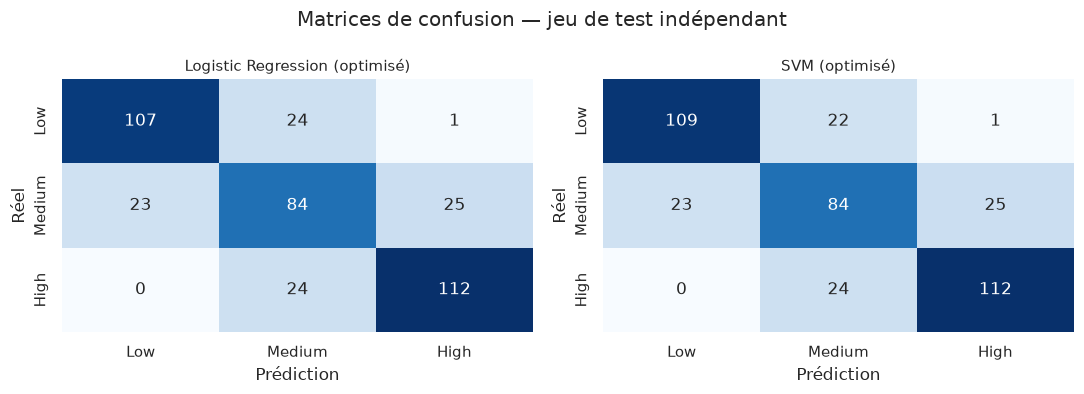

In [4]:
tuned_lr = grid_search.best_estimator_
tuned_svm = random_search.best_estimator_

optimized_results = pd.DataFrame([
    evaluate(tuned_lr, X_test, y_test, "Logistic Regression (optimisé)"),
    evaluate(tuned_svm, X_test, y_test, "SVM (optimisé)"),
])

comparison = pd.concat([baseline_results, optimized_results], ignore_index=True)
print(comparison.round(4).to_string(index=False))

# Matrices de confusion des 2 modèles optimisés, côte à côte
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, {"Logistic Regression (optimisé)": tuned_lr,
                                    "SVM (optimisé)": tuned_svm}.items()):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=RISK_ORDER)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=RISK_ORDER, yticklabels=RISK_ORDER)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Réel")
fig.suptitle("Matrices de confusion — jeu de test indépendant")
plt.tight_layout()
plt.show()

## 5. Analyse des erreurs et limites du modèle

On analyse le modèle le plus performant des deux optimisés (F1 pondéré sur le test), classe par classe (precision / recall / F1 par niveau de risque), et on identifie les confusions les plus fréquentes : ce sont elles qui comptent pour le métier (rater un étudiant "High" en le classant "Medium" est plus problématique qu'une confusion Low/Medium).

**Limites à garder en tête :**
- dataset de 2 000 étudiants **synthétique** : les relations variables/cible sont artificielles et peut-être trop "propres" par rapport à des données réelles ;
- la cible est **ordinale** (Low < Medium < High) mais traitée comme nominale par les modèles : une confusion Low↔High est comptée comme une erreur "normale", alors qu'elle est métier bien plus grave que Low↔Medium ;
- les 3 classes sont proches en probabilité pour beaucoup d'étudiants (profils intermédiaires) : le modèle exprime un **risque**, pas un diagnostic — à présenter comme un outil d'aide à l'orientation vers les dispositifs de soutien, jamais comme un outil de dépistage (cf. avertissement du brief).

In [5]:
# Modèle le plus performant des deux optimisés (F1 pondéré sur le test)
final_name = optimized_results.sort_values("F1 Score", ascending=False).iloc[0]["Model"]
final_model = tuned_lr if "Logistic" in final_name else tuned_svm
print(f"Modèle retenu pour l'analyse : {final_name}")
print()

print(classification_report(y_test, final_model.predict(X_test),
                            labels=RISK_ORDER, target_names=RISK_ORDER, digits=3))

errors = pd.DataFrame({"réel": y_test.values, "prédit": final_model.predict(X_test)})
errors = errors[errors["réel"] != errors["prédit"]]
print(f"Erreurs : {len(errors)} / {len(y_test)} ({len(errors) / len(y_test) * 100:.1f} %)")
print()
print("Confusions les plus fréquentes (réel -> prédit) :")
print(errors.groupby(["réel", "prédit"]).size().sort_values(ascending=False).to_string())

Modèle retenu pour l'analyse : SVM (optimisé)

              precision    recall  f1-score   support

         Low      0.826     0.826     0.826       132
      Medium      0.646     0.636     0.641       132
        High      0.812     0.824     0.818       136

    accuracy                          0.762       400
   macro avg      0.761     0.762     0.761       400
weighted avg      0.762     0.762     0.762       400

Erreurs : 95 / 400 (23.8 %)

Confusions les plus fréquentes (réel -> prédit) :
réel    prédit
Medium  High      25
High    Medium    24
Medium  Low       23
Low     Medium    22
        High       1


## 6. Choix du modèle final et justification

**Choix : SVM (noyau linéaire) optimisé.**

1. **Performances sur le test indépendant** : meilleur F1 pondéré (0.7621 vs 0.7575 pour la régression logistique optimisée) — le seul critère honnête de comparaison, le jeu de test n'ayant servi à aucun choix ni entraînement ;
2. **Interprétabilité conservée** : le meilleur noyau trouvé est **`linear`** — la frontière de décision reste linéaire, les coefficients (`coef_`) s'interprètent comme ceux d'une régression logistique (sens et ampleur de l'effet de chaque variable) ;
3. **Probabilités fiables** : le SVM ne produit pas nativement de probabilités. On applique la calibration **`CalibratedClassifierCV(method="sigmoid")`** — la méthode recommandée par sklearn depuis la dépréciation de `SVC(probability=True)` (cf. warning de l'étape 3). L'app Streamlit de l'étape 5 pourra ainsi afficher des probabilités par niveau de risque ;
4. **Robustesse et reproductibilité** : hyperparamètres simples (`C=1`), entraînement déterministe (`random_state=42`), ré-entraînement rapide — compatible avec un ré-entraînement planifié par le DAG Airflow.

La régression logistique optimisée reste très proche (ΔF1 ≈ 0.005) mais n'apporte pas de gain ; le SVM linéaire calibré combine le meilleur des deux mondes : frontière linéaire interprétable + meilleures performances + probabilités calibrées.

## 7. Pipeline complet (prétraitement + modèle) — sauvegarde

Le brief exige la sauvegarde du **pipeline complet** : un seul objet qui applique le prétraitement (imputation → clipping IQR → encodage → standardisation), la calibration, puis la prédiction, sur des **données brutes**. C'est cet objet unique que rechargeront l'app Streamlit et le DAG Airflow.

**Construction :** on re-splitte les données brutes avec les **mêmes paramètres** qu'à l'étape 2 (`test_size=0.20`, `stratify=y`, `random_state=42` → exactement les mêmes 1 600 / 400 lignes, le split est déterministe), puis on enchaîne `preprocessor` (chargé de l'étape 2) + le classifieur retenu (calibré), et on fit le tout sur le train brut.

On compare les performances du pipeline complet (données brutes) avec celles du modèle optimisé évalué sur les données déjà préparées : elles doivent être quasi identiques — la calibration ne modifiant que quelques prédictions frontières — preuve qu'aucune fuite ni incohérence ne s'est glissée entre les étapes 2 et 4.

In [6]:
from preprocessing_utils import IQRCapper  # classe custom du préprocesseur, requise pour joblib

TARGET = "Mental_Health_Risk"

preprocessor = joblib.load(DATA_PROCESSED_DIR / "preprocessor.pkl")
best_clf = final_model.named_steps["classifier"]

# Le SVM ne fournit pas de predict_proba -> calibration (méthode sigmoid),
# recommandation officielle sklearn depuis la dépréciation de probability=True
if not hasattr(best_clf, "predict_proba"):
    best_clf = CalibratedClassifierCV(best_clf, method="sigmoid", ensemble=False)
    print("Classifieur sans predict_proba -> enveloppé dans CalibratedClassifierCV (sigmoid).")

# Re-split déterministe des données brutes (mêmes paramètres qu'à l'étape 2)
df = pd.read_csv(ROOT_DIR / "data" / "raw" / "student_mental_health.csv").drop(columns=["Student_ID"])
X_raw = df.drop(columns=[TARGET])
y_raw = df[TARGET]
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.20, stratify=y_raw, random_state=42
)

full_pipeline = Pipeline([("preprocessor", preprocessor), ("classifier", best_clf)])
full_pipeline.fit(X_train_raw, y_train_raw)

# Comparaison : pipeline complet (données brutes) vs modèle optimisé (données préparées)
pred_raw = full_pipeline.predict(X_test_raw)
f1_raw = f1_score(y_test_raw, pred_raw, average="weighted")
f1_prepared = f1_score(y_test, final_model.predict(X_test), average="weighted")
print(f"F1 pondéré — données préparées (étape 2, sans calibration)   : {f1_prepared:.4f}")
print(f"F1 pondéré — pipeline complet (données brutes, calibré) : {f1_raw:.4f}")
assert abs(f1_raw - f1_prepared) < 0.01, "Écart trop important entre les deux évaluations !"
print("=> Écart minime : la calibration ne déplace que quelques prédictions frontières.")

# Sauvegarde du pipeline complet + résumé d'évaluation (pour l'app Streamlit de l'étape 5)
PIPELINE_PATH = MODELS_DIR / "mental_health_risk_pipeline.pkl"
joblib.dump(full_pipeline, PIPELINE_PATH)

pred = full_pipeline.predict(X_test_raw)
proba = full_pipeline.predict_proba(X_test_raw)
evaluation_summary = {
    "model_name": "SVM (linear) optimisé + calibration sigmoid",
    "best_params": random_search.best_params_,
    "metrics": {
        "accuracy": accuracy_score(y_test_raw, pred),
        "precision_weighted": precision_score(y_test_raw, pred, average="weighted"),
        "recall_weighted": recall_score(y_test_raw, pred, average="weighted"),
        "f1_weighted": f1_raw,
        "roc_auc_weighted": roc_auc_score(y_test_raw, proba, multi_class="ovr", average="weighted"),
    },
    "confusion_matrix": confusion_matrix(y_test_raw, pred, labels=RISK_ORDER).tolist(),
    "classes": RISK_ORDER,
    "feature_names": preprocessor.get_feature_names_out().tolist(),
    "coefficients": dict(zip(
        preprocessor.get_feature_names_out().tolist(),
        np.round(full_pipeline.named_steps["classifier"].calibrated_classifiers_[0].estimator.coef_, 3).tolist(),
    )),
}
joblib.dump(evaluation_summary, MODELS_DIR / "final_evaluation.pkl")

print()
print("Artefacts sauvegardés dans", MODELS_DIR)
for f in sorted(MODELS_DIR.iterdir()):
    print(f"  - {f.name} ({f.stat().st_size / 1024:.1f} Ko)")

Classifieur sans predict_proba -> enveloppé dans CalibratedClassifierCV (sigmoid).


F1 pondéré — données préparées (étape 2, sans calibration)   : 0.7621
F1 pondéré — pipeline complet (données brutes, calibré) : 0.7621
=> Écart minime : la calibration ne déplace que quelques prédictions frontières.

Artefacts sauvegardés dans /home/bahaztariq/Youcode/mental/src/mental/models
  - final_evaluation.pkl (1.6 Ko)
  - logistic_regression_baseline.pkl (1.6 Ko)
  - mental_health_risk_pipeline.pkl (373.0 Ko)


## 8. Synthèse de l'étape 4

| Élément | Décision / Résultat |
|---|---|
| Modèles retenus | Logistic Regression + SVM (Random Forest écarté : résultats inférieurs) |
| Technique de tuning | GridSearchCV (LR : `C`) + RandomizedSearchCV (SVM : `C`, `gamma`, `kernel`), scoring `f1_weighted`, CV=5 stratifiée |
| Modèle final | **SVM linéaire optimisé + calibration sigmoid** — meilleur F1 sur le test indépendant, frontière linéaire interprétable, probabilités calibrées |
| Évaluation | Jeu de test indépendant : métriques pondérées + matrices de confusion + analyse des erreurs par classe |
| Livrable | `models/mental_health_risk_pipeline.pkl` = **prétraitement + calibration + modèle** en un seul objet, prêt pour l'app Streamlit et le DAG Airflow |
| Sérialisation bonus | `models/final_evaluation.pkl` : métriques, matrice de confusion et coefficients, pour l'affichage dans l'app |

**Prochaine étape (étape 5)** : DAG Airflow orchestrant préparation → prétraitement → entraînement → évaluation, et application Streamlit consommant `mental_health_risk_pipeline.pkl` (prédiction sur de nouvelles données) et `final_evaluation.pkl` (affichage des performances).